# Can Speculative Crowding Improve Commodity ETF Momentum?

**Research question:** Does using CFTC speculative crowding to time exposure to a commodity ETF momentum portfolio improve the performance of a conventional cross-sectional momentum strategy?


| | Strategy 1 — Classical momentum | Strategy 2 — Crowding-conditioned momentum |
|---|---|---|
| Ranking signal | 12–1-month momentum | Same 12–1-month momentum |
| Portfolio | 6 highest-scoring ETFs long, 6 lowest short | Same portfolio when crowding is low; cash otherwise |
| Weight | $+1/6$ or $-1/6$ | Same when invested; zero otherwise |
| Rebalance | Monthly | Monthly |


**Reference:** Kang, W., Rouwenhorst, K. G., and Tang, K. (2021), *Crowding and Factor Returns*. This ETF portfolio is an adaptation, not a replication of their futures-portfolios study.

## 1. Research design and anti-leakage rules

1. **Investment universe:** 12 US-listed commodity ETFs, with adjusted USD closing prices. 
2. **Momentum:** 12–1 months: $MOM_{i,t}=P_{i,t-1}/P_{i,t-12}-1$ (omit most recent month).
3. **CFTC crowding:** Disaggregated — Futures & Options Combined **Managed Money** net positions, normalized by open interest and demeaned relative to 52 previous weekly observations.
5. **Two strategies, one comparison:** the same 6/6 equal-weight long–short portfolio, held continuously or only in low-crowding regimes, with identical dates, transaction costs and borrow assumptions.

Data sources: [CFTC disaggregated combined](https://publicreporting.cftc.gov/Commitments-of-Traders/Disaggregated-Combined/kh3c-gbw2), [CFTC release schedule](https://www.cftc.gov/MarketReports/CommitmentsofTraders/ReleaseSchedule/index.htm), [Yahoo via yfinance](https://github.com/ranaroussi/yfinance).

## 2. Environment and ETF universe


In [1]:
from pathlib import Path
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 35)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': True, 'grid.alpha': 0.22})

DATA_DIR = Path('data')
OUT_DIR = Path('outputs')
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

START_DATE = '2010-01-01'
END_DATE_EXCLUSIVE = '2026-11-01'
TEST_FIRST_RETURN = pd.Timestamp('2023-01-31')
N_LONG = N_SHORT = 6
COST_BPS = 5.0           # illustrative charge per dollar of traded notional
BORROW_BPS_YEAR = 100.0  # illustrative annual borrow fee on gross short notional
COT_AVAIL_LAG_DAYS = 7   # conservative proxy for knowledge date
COT_MAX_STALENESS_DAYS = 35
CROWDING_LOOKBACK_WEEKS = 52

ETF_CODES = {
    'USO': '067651', 'UNG': '023651', 'UGA': '111659',
    'CPER': '085692', 'CORN': '002602', 'WEAT': '001602',
    'SOYB': '005602', 'CANE': '080732', 'GLD': '088691',
    'SLV': '084691', 'PPLT': '076651', 'PALL': '075651',
}
TICKERS = list(ETF_CODES)
assert len(ETF_CODES) == 12 and len(set(ETF_CODES.values())) == 12
print('Assets:', ', '.join(TICKERS))
print('Test period: 2023-01 to 2026-10 (realized monthly returns)')


Assets: USO, UNG, UGA, CPER, CORN, WEAT, SOYB, CANE, GLD, SLV, PPLT, PALL
Test period: 2023-01 to 2026-10 (realized monthly returns)


## 3. Download CFTC Managed Money positions

The market codes identify the corresponding **commodity futures markets**.

In [ ]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

CFTC_URL = 'https://publicreporting.cftc.gov/resource/kh3c-gbw2.json'
CFTC_CACHE = DATA_DIR / 'cftc_disaggregated_combined_12_markets.csv'


CORE_FIELDS = {
    'report_date_as_yyyy_mm_dd': 'Date',
    'cftc_contract_market_code': 'MarketCode',
    'commodity_name': 'Commodity',
    'market_and_exchange_names': 'Market',
    'open_interest_all': 'OI',
    'm_money_positions_long_all': 'MM_Long',
    'm_money_positions_short_all': 'MM_Short',
}

EXTRA_FIELDS = {
    'change_in_open_interest_all': 'dOI',
    'm_money_positions_spread': 'MM_Spread',
    'change_in_m_money_long_all': 'dMM_Long',
    'change_in_m_money_short_all': 'dMM_Short',
    'prod_merc_positions_long': 'Commercial_Long',
    'prod_merc_positions_short': 'Commercial_Short',
    'swap_positions_long_all': 'Swap_Long',
    'swap__positions_short_all': 'Swap_Short',
    'traders_m_money_long_all': 'N_MM_Long',
    'traders_m_money_short_all': 'N_MM_Short',
    'conc_net_le_4_tdr_long_all': 'Conc4_Long',
    'conc_net_le_4_tdr_short_all': 'Conc4_Short',
}

def fetch_cftc(field_map):
    retries = Retry(total=4, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
    session = requests.Session()
    session.mount('https://', HTTPAdapter(max_retries=retries))
    quoted_codes = ','.join(f"'{x}'" for x in ETF_CODES.values())
    result = []
    offset, limit = 0, 5000
    while True:
        params = {
            '$select': ','.join(field_map),
            '$where': (
                f'cftc_contract_market_code IN ({quoted_codes}) '
                f"AND report_date_as_yyyy_mm_dd >= '{START_DATE}T00:00:00' "
                f"AND report_date_as_yyyy_mm_dd < '{END_DATE_EXCLUSIVE}T00:00:00'"
            ),
            '$order': 'report_date_as_yyyy_mm_dd ASC, cftc_contract_market_code ASC',
            '$limit': limit, '$offset': offset,
        }
        response = session.get(CFTC_URL, params=params, timeout=90)
        response.raise_for_status()
        batch = response.json()
        result.extend(batch)
        if len(batch) < limit:
            break
        offset += len(batch)
    if not result:
        raise ValueError('CFTC API returned no observations. Check mapping and API availability.')
    frame = pd.DataFrame(result).rename(columns=field_map)
    frame['MarketCode'] = frame['MarketCode'].astype('string').str.zfill(6)
    frame['ETF'] = frame['MarketCode'].map({v: k for k, v in ETF_CODES.items()})
    frame['Date'] = pd.to_datetime(frame['Date'])
    for col in field_map.values():
        if col not in ['Date', 'MarketCode', 'Commodity', 'Market'] and col in frame:
            frame[col] = pd.to_numeric(frame[col], errors='coerce')
    frame = frame.sort_values(['ETF', 'Date']).reset_index(drop=True)
    return frame

if CFTC_CACHE.exists():
    cftc_raw = pd.read_csv(CFTC_CACHE, dtype={'MarketCode': 'string'}, parse_dates=['Date'])
    print('Loaded CFTC cache:', CFTC_CACHE)
else:
    try:
        cftc_raw = fetch_cftc({**CORE_FIELDS, **EXTRA_FIELDS})
    except requests.HTTPError as exc:
        warnings.warn(f'Extended CFTC column selection failed: {exc}; trying core fields only.')
        cftc_raw = fetch_cftc(CORE_FIELDS)
    cftc_raw.to_csv(CFTC_CACHE, index=False)
    print('CFTC observations downloaded:', len(cftc_raw))

missing_tickers = sorted(set(TICKERS) - set(cftc_raw['ETF'].dropna()))
if missing_tickers:
    raise ValueError(f'Missing CFTC markets: {missing_tickers}. Review mapping before trading.')
if cftc_raw.duplicated(['ETF', 'Date']).any():
    duplicates = cftc_raw.loc[cftc_raw.duplicated(['ETF', 'Date'], keep=False), ['ETF','Date','Market']]
    raise ValueError(f'Multiple CFTC rows per ETF/date: inspect these entries:\n{duplicates.head(20)}')

coverage = cftc_raw.groupby('ETF').agg(Start=('Date','min'), End=('Date','max'), N=('Date','size'))
markets = cftc_raw[['ETF','MarketCode','Market']].drop_duplicates()
display(coverage.reindex(TICKERS))
display(markets.sort_values('ETF').reset_index(drop=True))

Loaded CFTC cache: data\cftc_disaggregated_combined_12_markets.csv


,Start,End,N
ETF,,,
USO,2010-01-05,2026-10-27,878
UNG,2010-01-05,2026-10-27,878
UGA,2010-01-05,2026-10-27,878
CPER,2010-01-05,2026-10-27,878
CORN,2010-01-05,2026-10-27,878
WEAT,2010-01-05,2026-10-27,878
SOYB,2010-01-05,2026-10-27,878
CANE,2010-01-05,2026-10-27,878
GLD,2010-01-05,2026-10-27,878


,ETF,MarketCode,Market
0,CANE,080732,SUGAR NO. 11 - ICE FUTURES U.S.
1,CORN,002602,CORN - CHICAGO BOARD OF TRADE
2,CPER,085692,COPPER-GRADE #1 - COMMODITY EXCHANGE INC.
3,CPER,085692,COPPER- #1 - COMMODITY EXCHANGE INC.
4,GLD,088691,GOLD - COMMODITY EXCHANGE INC.
5,PALL,075651,PALLADIUM - NEW YORK MERCANTILE EXCHANGE
6,PPLT,076651,PLATINUM - NEW YORK MERCANTILE EXCHANGE
7,SLV,084691,SILVER - COMMODITY EXCHANGE INC.
8,SOYB,005602,SOYBEANS - CHICAGO BOARD OF TRADE
9,UGA,111659,GASOLINE BLENDSTOCK (RBOB) - NEW YORK MERCANTI...


## 4. Construct the speculative crowding indicator

For commodity $i$ and report week $t$, normalized **Managed Money net speculative pressure** is:

$$
NP_{i,t}=\frac{MM^{long}_{i,t}-MM^{short}_{i,t}}{OI_{i,t}}
$$

The historical benchmark uses the **previous 52 weekly observations**, excluding the current week:

$$
\overline{NP}^{(52)}_{i,t}=\frac{1}{52}\sum_{k=1}^{52} NP_{i,t-k}
$$

The signed crowding indicator is:

$$
Crowding_{i,t}=NP_{i,t}-\overline{NP}^{(52)}_{i,t}
$$

Positive values indicate unusually net-long positioning; negative values indicate unusually net-short positioning. This is a **measured descriptive indicator**, not yet a return prediction. The formula and rolling history do not use information from the future.

In [3]:
crowding_data = (cftc_raw[['Date', 'ETF', 'OI', 'MM_Long', 'MM_Short']].copy().sort_values(['ETF', 'Date']))
crowding_data['NetPressure'] = (
    (crowding_data['MM_Long'] - crowding_data['MM_Short'])
    / crowding_data['OI'].replace(0, np.nan)
)
crowding_data['HistoricalPressure'] = (
    crowding_data.groupby('ETF')['NetPressure'].transform(
        lambda s: s.shift(1).rolling(
            CROWDING_LOOKBACK_WEEKS,
            min_periods=CROWDING_LOOKBACK_WEEKS
        ).mean()
    )
)
crowding_data['Crowding'] = (
    crowding_data['NetPressure'] - crowding_data['HistoricalPressure']
)

crowding_data['dPressure'] = (
    crowding_data.groupby('ETF')['NetPressure'].diff()
)

crowding_data['AvailableAt'] = (
    crowding_data['Date'] + pd.Timedelta(days=COT_AVAIL_LAG_DAYS)
)


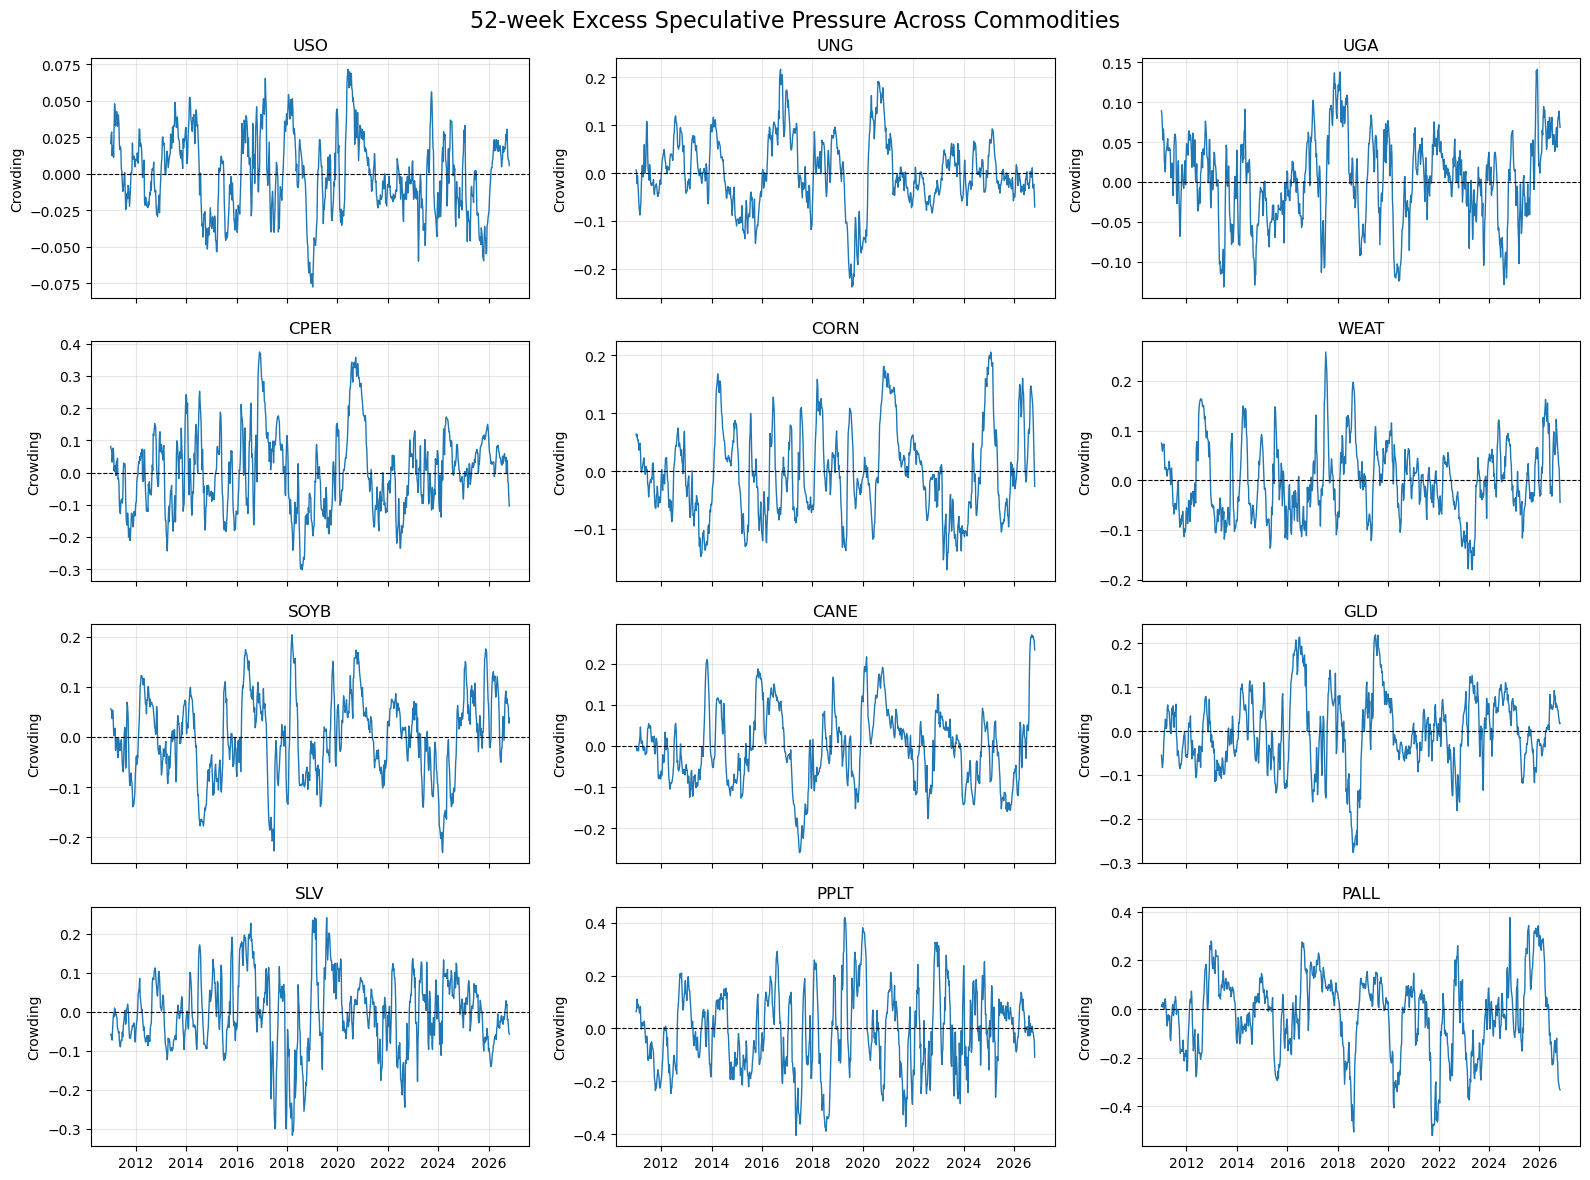

In [4]:
# Plot crowding for all 12 ETFs

fig, axes = plt.subplots(4, 3, figsize=(16, 12), sharex=True)

axes = axes.flatten()

for ax, ticker in zip(axes, TICKERS):
    series = (
        crowding_data.loc[crowding_data['ETF'].eq(ticker)]
        .set_index('Date')['Crowding']
    )

    ax.plot(series.index, series, lw=1)
    ax.axhline(0, color='black', linestyle='--', lw=0.8)

    ax.set_title(ticker)
    ax.set_ylabel('Crowding')
    ax.grid(alpha=0.3)

fig.suptitle(
    '52-week Excess Speculative Pressure Across Commodities',
    fontsize=16
)

plt.tight_layout()
plt.show()



## 5. Download adjusted ETF prices

We use adjusted daily closing prices, resampled to monthly closes.

Loaded price cache: data\etf_adjusted_close_daily.csv


,First,Last,Valid days
USO,2010-01-04,2026-10-30,4233
UNG,2010-01-04,2026-10-30,4233
UGA,2010-01-04,2026-10-30,4233
CPER,2011-11-15,2026-10-30,3761
CORN,2010-06-09,2026-10-30,4125
WEAT,2011-09-19,2026-10-30,3802
SOYB,2011-09-19,2026-10-30,3802
CANE,2011-09-19,2026-10-30,3802
GLD,2010-01-04,2026-10-30,4233
SLV,2010-01-04,2026-10-30,4233


Monthly dates: 2010-01-31 to 2026-10-31


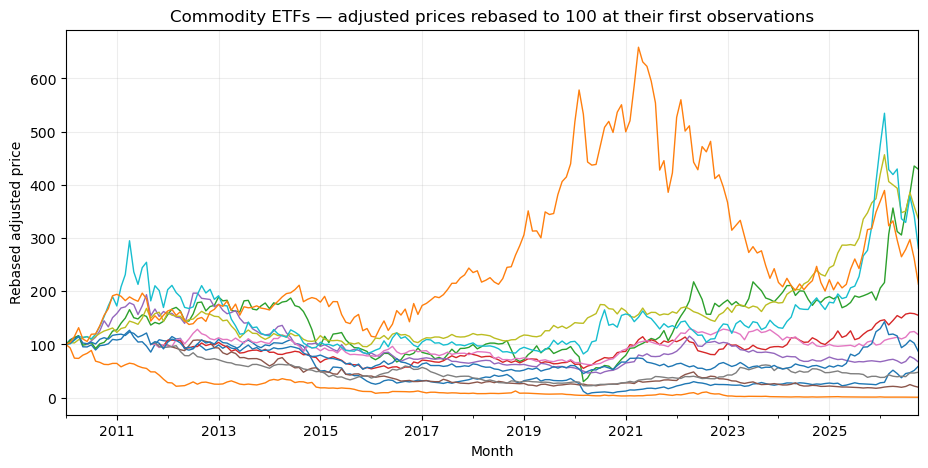

In [5]:
PRICE_CACHE = DATA_DIR / 'etf_adjusted_close_daily.csv'

if PRICE_CACHE.exists():
    daily_close = pd.read_csv(PRICE_CACHE, index_col=0, parse_dates=True)
    print('Loaded price cache:', PRICE_CACHE)
else:
    import yfinance as yf
    raw_prices = yf.download(
        tickers=TICKERS, start=START_DATE, end=END_DATE_EXCLUSIVE,
        auto_adjust=True, progress=False, group_by='column', threads=False
    )
    if raw_prices.empty:
        raise ValueError('No ETF prices retrieved from yfinance.')
    if isinstance(raw_prices.columns, pd.MultiIndex):
        if 'Close' in raw_prices.columns.get_level_values(0):
            daily_close = raw_prices['Close'].copy()
        else:
            daily_close = raw_prices.xs('Close', axis=1, level=1).copy()
    else:
        raise ValueError('Unexpected yfinance column format: check library version.')
    daily_close.index = pd.to_datetime(daily_close.index).tz_localize(None)
    daily_close.sort_index().to_csv(PRICE_CACHE)
    print('Downloaded price data:', PRICE_CACHE)

daily_close = daily_close.sort_index().reindex(columns=TICKERS)
daily_close = daily_close.loc[
    (daily_close.index >= pd.Timestamp(START_DATE)) &
    (daily_close.index < pd.Timestamp(END_DATE_EXCLUSIVE))
]
if daily_close.empty:
    raise ValueError('ETF price panel is empty. Check price cache or Yahoo download.')
if (daily_close.notna().sum() < 250).any():
    raise ValueError('Insufficient ETF price observations for: ' +
                     str(daily_close.notna().sum().loc[lambda s: s < 250].to_dict()))

price_coverage = pd.DataFrame({
    'First': daily_close.apply(lambda s: s.first_valid_index()),
    'Last': daily_close.apply(lambda s: s.last_valid_index()),
    'Valid days': daily_close.notna().sum(),
})
display(price_coverage)

monthly_close = daily_close.resample('ME').last()
monthly_price_dates = pd.DataFrame({
    ticker: daily_close[ticker].dropna().index.to_series().resample('ME').last()
    for ticker in TICKERS
}).reindex(index=monthly_close.index, columns=monthly_close.columns)
monthly_returns = monthly_close.pct_change(fill_method=None)
print('Monthly dates:', monthly_close.index.min().date(), 'to', monthly_close.index.max().date())

fig, ax = plt.subplots()
rebased = monthly_close.div(monthly_close.ffill().apply(lambda s: s.dropna().iloc[0])) * 100
rebased.plot(ax=ax, lw=1, legend=False)
ax.set(title='Commodity ETFs — adjusted prices rebased to 100 at their first observations',
       ylabel='Rebased adjusted price', xlabel='Month')
plt.show()

## 6. Create the monthly signal panel

At the end of month $t$, we compute momentum and pair it with **the latest CFTC signal** available by each ETF’s last trading session of that month. Both indicators are observed *before* the following month return $r_{i,t+1}$, used only for evaluation.

$$
MOM_{i,t}=\frac{P_{i,t-1}}{P_{i,t-12}}-1
$$

For descriptive comparison, we also cross-sectionally standardize momentum and crowding separately in each month; neither strategy uses these standardized scores to rank assets.

$$
z^{MOM}_{i,t}=\frac{MOM_{i,t}-\mu^{MOM}_t}{\sigma^{MOM}_t},\qquad
z^{CROWD}_{i,t}=\frac{Crowding_{i,t}-\mu^{CROWD}_t}{\sigma^{CROWD}_t}
$$

These cross-sectional means and standard deviations use **only the twelve ETFs' signals available at time $t$**. The test month return is never used in signal construction.

In [6]:

mom_12_1 = monthly_close.shift(1).div(monthly_close.shift(12)) - 1
next_month_ret = monthly_returns.shift(-1)

def to_series(frame, name):
    return frame.stack(dropna=False).rename(name)

panel = pd.concat([
    to_series(monthly_close, 'Price'),
    to_series(monthly_price_dates, 'PriceDate'),
    to_series(mom_12_1, 'Momentum'),
    to_series(next_month_ret, 'NextReturn'),
], axis=1).reset_index().rename(columns={
    'level_0': 'Date',
    'level_1': 'ETF'
})

# Prepare crowding data for merging
crowding_available = crowding_data[
    ['ETF', 'Date', 'AvailableAt', 'NetPressure', 'Crowding']
].rename(columns={'Date': 'CFTC_ReportDate'})

# Merge monthly ETF data with available crowding observations
panel = pd.merge_asof(
    panel.loc[panel['PriceDate'].notna()].sort_values(['PriceDate', 'ETF']),
    crowding_available.sort_values(['AvailableAt', 'ETF']),
    by='ETF',
    left_on='PriceDate',
    right_on='AvailableAt',
    direction='backward',
    tolerance=pd.Timedelta(days=COT_MAX_STALENESS_DAYS)
)

assert (
    panel.loc[panel['AvailableAt'].notna(), 'AvailableAt']
    <= panel.loc[panel['AvailableAt'].notna(), 'PriceDate']
).all()
assert panel['PriceDate'].dt.to_period('M').eq(panel['Date'].dt.to_period('M')).all()

# Cross-sectional normalization
def cross_sectional_zscore(s):
    std = s.std(ddof=0)
    if not np.isfinite(std) or std < 1e-12:
        return pd.Series(np.nan, index=s.index)
    return (s - s.mean()) / std

panel['Momentum_z'] = (
    panel.groupby('Date')['Momentum']
    .transform(cross_sectional_zscore)
)

panel['Crowding_z'] = (
    panel.groupby('Date')['Crowding']
    .transform(cross_sectional_zscore)
)

panel['ReturnMonth'] = panel['Date'] + pd.offsets.MonthEnd(1)

# Keep only months with 12 complete ETF observations
needed = [
    'Momentum', 'Crowding',
    'Momentum_z', 'Crowding_z', 'NextReturn'
]

counts = (
    panel.dropna(subset=needed)
    .groupby('Date')['ETF']
    .nunique()
)

valid_dates = counts[counts == len(TICKERS)].index

panel = (
    panel.loc[panel['Date'].isin(valid_dates)]
    .sort_values(['Date', 'ETF'])
    .copy()
)

if panel.empty:
    raise ValueError(
        'No fully matched 12-ETF signal months. '
        'Inspect missing prices/CFTC reports.'
    )

assert panel.groupby('Date')['ETF'].nunique().eq(12).all()
assert panel[needed].notna().all().all()

print('Usable monthly signals:', panel.Date.nunique())
print('First:', panel.Date.min().date(), '| Last:', panel.Date.max().date())

display(panel[
    ['Date', 'ETF', 'Momentum', 'Crowding',
     'Momentum_z', 'Crowding_z', 'NextReturn']
].head(12))


C:\Users\ibrah\AppData\Local\Temp\ipykernel_9184\398259171.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return frame.stack(dropna=False).rename(name)
C:\Users\ibrah\AppData\Local\Temp\ipykernel_9184\398259171.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  return frame.stack(dropna=False).rename(name)
C:\Users\ibrah\AppData\Local\Temp\ipykernel_9184\398259171.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True

Usable monthly signals: 167
First: 2012-11-30 | Last: 2026-09-30


,Date,ETF,Momentum,Crowding,Momentum_z,Crowding_z,NextReturn
321,2012-11-30,CANE,-0.250641,-0.057867,-1.449461,-1.584491,0.017684
322,2012-11-30,CORN,0.215964,0.022187,1.308964,-0.007515,-0.073772
323,2012-11-30,CPER,-0.021825,-0.043180,-0.096774,-1.295169,-0.009505
324,2012-11-30,GLD,-0.019397,0.017931,-0.082418,-0.091353,-0.024270
325,2012-11-30,PALL,-0.016469,0.117622,-0.065109,1.872409,0.029753
326,2012-11-30,PPLT,0.003574,0.079247,0.053378,1.116488,-0.038618
327,2012-11-30,SLV,-0.022812,0.064464,-0.102609,0.825273,-0.092398
328,2012-11-30,SOYB,0.245202,-0.025807,1.481811,-0.952949,-0.017952
329,2012-11-30,UGA,0.176017,0.018143,1.072812,-0.087183,0.013001
330,2012-11-30,UNG,-0.309403,0.054431,-1.796846,0.627636,-0.073075


## 7. Strategy 1 — classical cross-sectional momentum

At each month-end, sort the twelve ETFs by **12–1 momentum** and allocate:

- **Long** the 6 best performers at $+1/6$ each.
- **Short** the 6 worst performers at $-1/6$ each.

The portfolio is dollar neutral with **gross exposure 200%**, which implies leverage in the simplified long–short accounting; the crowding-conditioned strategy has the same exposure when invested and zero exposure in cash months.

In [7]:
def six_six_weights(df, score_col):
    scores = df.pivot(index='Date', columns='ETF', values=score_col).reindex(columns=TICKERS)
    if scores.isna().any().any():
        raise ValueError(f'Missing {score_col} in a 6/6 portfolio month.')
    ranks = scores.rank(axis=1, method='first', ascending=False)
    weights = pd.DataFrame(-1.0 / N_SHORT, index=scores.index, columns=scores.columns)
    weights[ranks <= N_LONG] = 1.0 / N_LONG
    assert np.allclose(weights.sum(axis=1), 0)
    assert np.allclose(weights.abs().sum(axis=1), 2)
    assert (weights.gt(0).sum(axis=1) == 6).all()
    assert (weights.lt(0).sum(axis=1) == 6).all()
    return weights

all_classic_weights = six_six_weights(panel, 'Momentum')
display(all_classic_weights.tail(4).style.format('{:+.1%}'))

ETF,USO,UNG,UGA,CPER,CORN,WEAT,SOYB,CANE,GLD,SLV,PPLT,PALL
Date,,,,,,,,,,,,
2026-06-30 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,-16.7%,-16.7%,-16.7%,+16.7%,+16.7%,+16.7%,-16.7%
2026-07-31 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,-16.7%,-16.7%,-16.7%,+16.7%,+16.7%,+16.7%,-16.7%
2026-08-31 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,-16.7%,-16.7%,-16.7%,+16.7%,+16.7%,+16.7%,-16.7%
2026-09-30 00:00:00,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,+16.7%,+16.7%,-16.7%,-16.7%,+16.7%,-16.7%,-16.7%


## 8. Strategy 2 — momentum conditioned on **portfolio-level** crowding

This follows the **regime-conditioning** mechanism in Kang, Rouwenhorst & Tang (2021), section 4.2 / Figure 2, rather than changing ETF rankings.

First, construct the *same* classical 6-long/6-short momentum portfolio. Next, calculate its **signed, factor-level crowding**, corresponding to equation (5) of the paper:

$$
C^{MOM}_t = \frac{1}{2}\left(\frac{1}{6}\sum_{i\in Long_t}C_{i,t}
-\frac{1}{6}\sum_{i\in Short_t}C_{i,t}\right).
$$

The minus sign for the short leg is essential: unusually net-short speculative positioning in an asset we short **increases** the crowding of the factor strategy.

We then calculate the **trailing three-year benchmark**, with the present month strictly excluded:

$$
\overline C^{MOM,(36)}_t = \frac{1}{36}\sum_{k=1}^{36}C^{MOM}_{t-k}.
$$

Finally, the second strategy uses *identical holdings* to the classical momentum strategy **only in low-crowding regimes**:

$$
w^{conditional}_{i,t} =
\begin{cases}
w^{MOM}_{i,t}, & C^{MOM}_t < \overline C^{MOM,(36)}_t,\\
0, & \text{otherwise}.
\end{cases}
$$

The **zero-weight** case is a full cash month (assumed cash return = 0). There is **no $\lambda$, no asset re-ranking, no Ridge, and no XGBoost**.

**Article vs our adaptation:** the article classifies regimes using the momentum factor crowding relative to its **past 156-week average** and holds weekly futures portfolios. We implement **36 prior monthly observations** for a monthly ETF portfolio. That is the same *principle* at a different frequency, not an identical empirical replication.


OOS realized return months: 2023-01-31 to 2026-10-31
Number of comparison months: 46
Fraction of months invested: 52.2%


,FactorCrowding,Past3YearAverage,Invested
2025-12-31,0.048246,0.019211,False
2026-01-31,0.019508,0.021983,True
2026-02-28,0.008501,0.023134,True
2026-03-31,-0.026733,0.021955,True
2026-04-30,-0.009130,0.020088,True
2026-05-31,-0.030673,0.018068,True
2026-06-30,0.037107,0.015733,False
2026-07-31,0.015899,0.015234,False
2026-08-31,-0.007218,0.014376,True
2026-09-30,0.005986,0.014570,True


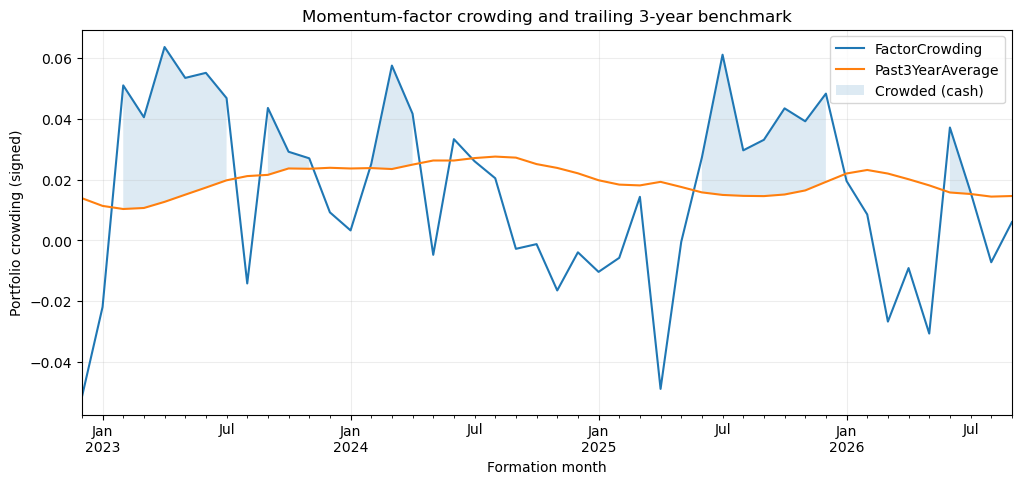

,Momentum,CommodityCrowding,ClassicalWeight,ConditionalWeight
ETF,,,,
UGA,1.0036,0.0756,0.1667,0.1667
USO,0.8129,0.0305,0.1667,0.1667
SLV,0.4192,0.0200,0.1667,0.1667
WEAT,0.3533,0.0654,0.1667,0.1667
CPER,0.3333,0.0387,0.1667,0.1667
SOYB,0.2693,0.0767,0.1667,0.1667
CORN,0.1496,0.1238,-0.1667,-0.1667
GLD,0.1490,0.0475,-0.1667,-0.1667
PPLT,0.1373,0.0087,-0.1667,-0.1667


In [ ]:
FACTOR_CROWDING_LOOKBACK_MONTHS = 36 
crowding_wide_all = (
    panel.pivot(index='Date', columns='ETF', values='Crowding')
    .reindex(index=all_classic_weights.index, columns=all_classic_weights.columns)
)
assert crowding_wide_all.notna().all().all()

factor_crowding = 0.5 * (all_classic_weights * crowding_wide_all).sum(axis=1)
factor_crowding.name = 'FactorCrowding'

# Previous 36 monthly signals
factor_crowding_threshold = (
    factor_crowding.rolling(
        FACTOR_CROWDING_LOOKBACK_MONTHS,
        min_periods=FACTOR_CROWDING_LOOKBACK_MONTHS
    ).mean().shift(1)
)
factor_crowding_threshold.name = 'Past3YearAverage'

low_crowding = factor_crowding.lt(factor_crowding_threshold)
low_crowding.name = 'Invested'

all_conditional_weights = all_classic_weights.mul(low_crowding.astype(float), axis=0)

valid_regime_dates = factor_crowding_threshold.dropna().index
test = panel.loc[
    (panel['ReturnMonth'] >= TEST_FIRST_RETURN)
    & panel['Date'].isin(valid_regime_dates)
].copy()
if test.empty:
    raise ValueError('No months with a valid three-year historical crowding threshold.')

signal_dates = pd.DatetimeIndex(test['Date'].unique()).sort_values()
w_momentum = all_classic_weights.loc[signal_dates]
w_enhanced = all_conditional_weights.loc[signal_dates]
assert w_momentum.index.equals(w_enhanced.index)
assert np.allclose(w_enhanced.loc[low_crowding.loc[signal_dates]],
                   w_momentum.loc[low_crowding.loc[signal_dates]])
assert np.allclose(w_enhanced.loc[~low_crowding.loc[signal_dates]], 0)

print('OOS realized return months:', test.ReturnMonth.min().date(), 'to',
      test.ReturnMonth.max().date())
print('Number of comparison months:', len(signal_dates))
print('Fraction of months invested:', f'{low_crowding.loc[signal_dates].mean():.1%}')

regimes = pd.DataFrame({
    'FactorCrowding': factor_crowding.loc[signal_dates],
    'Past3YearAverage': factor_crowding_threshold.loc[signal_dates],
    'Invested': low_crowding.loc[signal_dates],
})
display(regimes.tail(10))

fig, ax = plt.subplots(figsize=(12, 5))
regimes[['FactorCrowding', 'Past3YearAverage']].plot(ax=ax, lw=1.5)
ax.fill_between(regimes.index, regimes['FactorCrowding'], regimes['Past3YearAverage'],
                where=~regimes['Invested'], alpha=0.15, label='Crowded (cash)')
ax.set(title='Momentum-factor crowding and trailing 3-year benchmark',
       ylabel='Portfolio crowding (signed)', xlabel='Formation month')
ax.legend()
plt.show()

# Last month: positions are either the classical holdings or all zero.
example_date = signal_dates[-1]
example = test.loc[test['Date'].eq(example_date)].set_index('ETF')
display(pd.DataFrame({
    'Momentum': example['Momentum'],
    'CommodityCrowding': example['Crowding'],
    'ClassicalWeight': w_momentum.loc[example_date],
    'ConditionalWeight': w_enhanced.loc[example_date],
}).sort_values('Momentum', ascending=False).round(4))


## 9. Backtest both strategies with identical trading-cost assumptions

With weights set at the end of month $t$, the *following month's* gross PnL proxy is:

$$
R^{gross}_{t+1}=\sum_i w_{i,t}r_{i,t+1}.
$$

Assumed rebalancing and borrowing costs are:

$$
TC_t=c\sum_i |w_{i,t}-\widetilde w_{i,t}|,\quad
R^{net}_{t+1}=R^{gross}_{t+1}-TC_t-\frac{b}{12}\sum_i\max(-w_{i,t},0).
$$

Here $c$ is a **hypothetical** charge per dollar traded (5 bps baseline) and $b$ is a **hypothetical** short borrow fee (100 bps/year). Here $\widetilde w_{i,t}$ denotes the pre-trade weights after return drift. Turnover accounts for the drift in portfolio weights due to the preceding month’s ETF returns, with the first test portfolio initiated from cash. Gross exposure is 200% while invested and zero in cash months; margin funding and collateral income are omitted, and closing-price execution is approximate.

In [ ]:
def backtest(weights, observations, cost_bps=COST_BPS, borrow_bps_year=BORROW_BPS_YEAR):
    realized = observations.pivot(index='Date', columns='ETF', values='NextReturn')
    realized = realized.reindex(index=weights.index, columns=weights.columns)
    if realized.isna().any().any():
        raise ValueError('Missing forward ETF returns in portfolio PnL.')
    gross = (weights * realized).sum(axis=1)
    prev = (
        weights.shift(1).mul(1 + realized.shift(1))
        .div(1 + gross.shift(1), axis=0)
        .fillna(0.0)
    )  # stand-alone test: establish portfolio from cash
    traded_notional = weights.sub(prev).abs().sum(axis=1)
    tc = (cost_bps / 10_000) * traded_notional
    short_exposure = -weights.clip(upper=0).sum(axis=1)
    borrow = (borrow_bps_year / 10_000 / 12) * short_exposure
    result = pd.DataFrame({
        'GrossReturn': gross, 'TransactionCost': tc,
        'BorrowCost': borrow, 'TradedNotional': traded_notional,
        'NetReturn': gross - tc - borrow,
    })
    result.index = result.index + pd.offsets.MonthEnd(1)  
    result.index.name = 'ReturnMonth'
    return result

def performance_metrics(bt):
    ret = bt.NetReturn.dropna()
    if not len(ret):
        return pd.Series(dtype=float)
    eq = (1 + ret).cumprod()
    eq_with_initial_cash = pd.concat([pd.Series([1.0]), eq.reset_index(drop=True)], ignore_index=True)
    dd = eq_with_initial_cash / eq_with_initial_cash.cummax() - 1
    annual_return = (float(eq.iloc[-1]) ** (12 / len(ret)) - 1) if (eq.iloc[-1] > 0) else np.nan
    vol = ret.std(ddof=1) * np.sqrt(12)
    return pd.Series({
        'Annual return': annual_return,
        'Annual volatility': vol,
        'Sharpe (rf=0)': (ret.mean() * 12 / vol) if vol > 0 else np.nan,
        'Maximum drawdown': dd.min(),
        'Positive months': (ret > 0).mean(),
        'Mean monthly traded notional': bt.TradedNotional.mean(),
        'Annualized trading costs': bt.TransactionCost.mean() * 12,
    })


bt_momentum = backtest(w_momentum, test)
bt_enhanced = backtest(w_enhanced, test)
assert bt_momentum.index.equals(bt_enhanced.index)
comparison = pd.concat({
    'Classical momentum 6/6': performance_metrics(bt_momentum),
    'Crowding-conditioned 6/6 (cash if high)': performance_metrics(bt_enhanced),
}, axis=1).T
print('OUT-OF-SAMPLE RESULTS — net of explicitly assumed costs')
display(comparison.round(4))


OUT-OF-SAMPLE RESULTS — net of explicitly assumed costs


,Annual return,Annual volatility,Sharpe (rf=0),Maximum drawdown,Positive months,Mean monthly traded notional,Annualized trading costs
Classical momentum 6/6,0.0434,0.2195,0.3029,-0.3136,0.5435,0.6362,0.0038
Crowding-conditioned 6/6 (cash if high),-0.0631,0.1704,-0.2943,-0.3490,0.2391,0.8129,0.0049


## 10. Compare returns, cumulative performance and turnover

Both strategies trade on precisely the **same set of dates** and use the same 6/6 portfolio construction. Comparing the equity curves, Sharpe ratios, drawdowns and turnover tells us whether the crowding filter adds value **after its trading costs**, not just whether it changes the time invested.

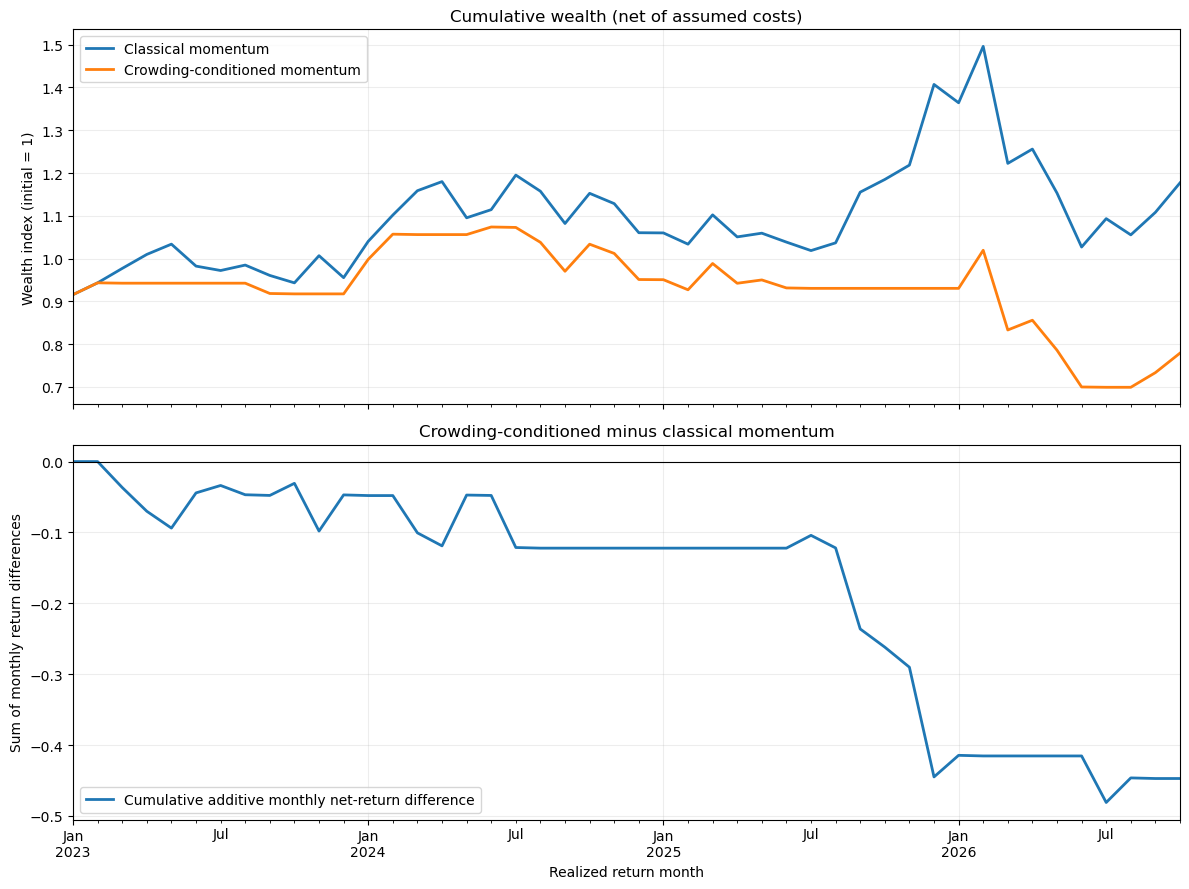

Invested share (conditional): 52.2%
Monthly traded notional relative to portfolio NAV:


,Classical momentum,Crowding-conditioned momentum
mean,0.636,0.813
50%,0.737,0.728
max,2.000,2.141


In [ ]:
returns = pd.concat({
    'Classical momentum': bt_momentum.NetReturn,
    'Crowding-conditioned momentum': bt_enhanced.NetReturn,
}, axis=1)

start_month = returns.index[0] - pd.offsets.MonthEnd(1)
wealth = (1 + returns).cumprod()
wealth.loc[start_month] = 1.0
wealth = wealth.sort_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
wealth.plot(ax=axes[0], lw=2)
axes[0].set(title='Cumulative wealth (net of assumed costs)',
            ylabel='Wealth index (initial = 1)')

monthly_uplift = returns.iloc[:, 1] - returns.iloc[:, 0]
monthly_uplift.cumsum().plot(
    ax=axes[1], lw=2,
    label='Cumulative additive monthly net-return difference'
)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set(title='Crowding-conditioned minus classical momentum',
            ylabel='Sum of monthly return differences', xlabel='Realized return month')
axes[1].legend()
plt.tight_layout()
plt.show()

turnover = pd.DataFrame({
    'Classical momentum': bt_momentum.TradedNotional,
    'Crowding-conditioned momentum': bt_enhanced.TradedNotional,
})
print('Invested share (conditional):', f'{low_crowding.loc[signal_dates].mean():.1%}')
print('Monthly traded notional relative to portfolio NAV:')
display(turnover.describe().loc[['mean', '50%', 'max']].round(3))
